# Chapter 1 - intro to ml

In [ ]:
# basic stuff only. can skip

# Chapter 2 - intro to linear regression 1

## Primary steps of building a regression model

In [ ]:
'''
1 - EDA
2 - encoding - convert categorical data into numerical data
3 - Scaling
4 - Train test split
5 - Call the model 
6 - train the dataset on train data
7 - Run the model on test data
'''


### Encoding

In [88]:
import pandas as pd
df_car=pd.read_csv(r"C:\Users\Mayank Bhatia\Documents\GitHub\DSML\13_intro_to_ml_nn\13.2_intro_to_ml_ml_linear_regression_1\cars24-car-price-cleaned.csv")

In [89]:
df_car.head() # need to encode make and model from this dataset

df_car['model']=df_car.groupby(['model'])['selling_price'].transform('mean')
df_car['make']=df_car.groupby(['make'])['selling_price'].transform('mean')

### Scaling 

In [90]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
df_car=pd.DataFrame(scaler.fit_transform(df_car),columns=df_car.columns)

In [17]:
df_car.head()

,selling_price,year,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,0.043684,0.689655,0.031553,0.135345,0.117891,0.066506,0.310345,0.041550,0.041550,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
1,0.252397,0.827586,0.005237,0.128448,0.177281,0.123994,0.172414,0.218382,0.218382,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
2,0.089795,0.620690,0.015764,0.112069,0.177281,0.120773,0.379310,0.149143,0.149143,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
3,0.095134,0.689655,0.009711,0.145862,0.147808,0.100000,0.310345,0.093193,0.093193,1.0,0.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0
4,0.262104,0.793103,0.007869,0.161810,0.221860,0.150709,0.206897,0.313574,0.313574,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0


### train test split

In [91]:
from sklearn.model_selection import train_test_split

y=df_car['selling_price']
x=df_car.drop(['selling_price'],axis=1)

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=True)

### Train the model

In [92]:
from sklearn.linear_model import LinearRegression
lm=LinearRegression()

lm.fit(x_train,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [93]:
print(lm.score(x_train,y_train))
print(lm.score(x_test,y_test))

0.9457591024750988
0.9458843076992296


# Chapter 3 - intro to linear regression 2

## Remember

In [ ]:
'''
measure of accuracy for a model = R square , that is 1-rss/tss
    rss = residual square sum = (sum(error^2))/n - square because it is differentiable
    tss - total sum of squares = sum(y'-y')^2/n where y'=mean

    
    tss - total variance in the target variable
    rss - variability unexplainiable by the model
    R square basically tells us how better our model is able to explain the variance/variability of the target variable

'''

## Creating my own model

<Axes: >

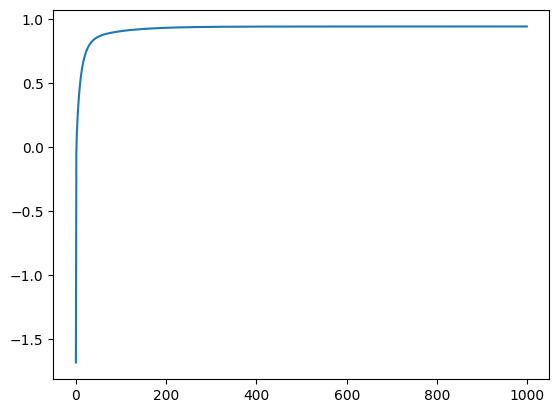

In [77]:
# revise the idea of gradient descent from the chapter file. see claude chat as well

import numpy as np 
import seaborn as sns
import warnings



k=0.1
iterations=1000

w=np.zeros(shape=x_train.shape[1])
w0=0
accu_series=np.zeros(shape=iterations)
for i in range(iterations):
    accu=1-(np.sum((y_train-x_train.dot(w)-w0)**2))/(np.sum((y_train-np.mean(y_train))**2))
    accu_series[i]=accu
    y_pred=x_train.dot(w)+w0
    w_diff=(-2*k*(x_train.T.dot(y_train-y_pred)))/x_train.shape[0]
    w0diff=(-2*k*np.sum(y_train-y_pred))/x_train.shape[0]
    w=w-w_diff
    w0=w0-w0diff

sns.lineplot(data=accu_series)


## Model interpretability

In [94]:
feature_importance=pd.DataFrame({'feature':x_train.columns,'importance':lm.coef_})

             feature  importance
0               year    0.125884
1          km_driven   -0.250170
2            mileage   -0.228541
3             engine    0.075084
4          max_power    0.045305
5                age   -0.125884
6               make    0.064606
7              model    0.860342
8         Individual   -0.007020
9   Trustmark Dealer   -0.007031
10            Diesel    0.006723
11          Electric    0.129215
12               LPG    0.016040
13            Petrol   -0.006619
14            Manual   -0.003905
15                 5   -0.016300
16                >5   -0.023593


<Axes: xlabel='feature', ylabel='importance'>

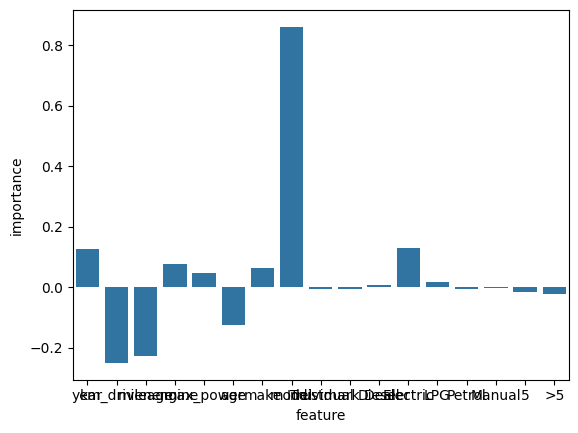

In [99]:
print(feature_importance)
sns.barplot(data=feature_importance,x='feature',y='importance')

# Chapter 4 - intro to linear regression 3

In [ ]:
''' 
Not so relevant stuff 
Statmodel - similar to sklearn linear regression
adjusted r square to account for irrelevant features
vif - variance inflation factor - measure of 2 features correlation 
    vif 1 - no correlation
    vif 1-5= moderate 
    vif 5-10= high correlation
    vif 10+= severe correlation 
'''

# Chapter 5 - intro to linear regression 4

In [100]:
'''
Assumptions before applying linear regression

1 - assumption of linearity
2 - no collinearity: basically low variance inflation factor
3 - normality of residual: errors should follow normal curve. if they are right/left skewed then there are some outliers that need to be catered
4 - errors should be randomly present across the spectrum of Ys
    Good example of spends vs income: low income folks spends are predictable but high income folks are unpredictable and hence high residual
5 - auto correlation - no relation of residuals. first residual should not explain another residual
    For example in time series data, for example panel data with repeated observations like in boxing matches
'''

'\nAssumptions before applying linear regression\n\n1 - assumption of linearity\n2 - no collinearity: basically low variance inflation factor\n3 - normality of residual: errors should follow normal curve. if they are right/left skewed then there are some outliers that need to be catered\n4 - errors should be randomly present across the spectrum of Ys\n    Good example of spends vs income: low income folks spends are predictable but high income folks are unpredictable and hence high residual\n5 - auto correlation - no relation of residuals. first residual should not explain another residual\n    For example in time series data, for example panel data with repeated observations like in boxing matches\n'

# Chapter 6 - intro to polynomial regression

In [1]:
'''
1 epoch = one complete cycle of weigh adjustments, that is model has scanned each data point at least once 
    batch gradient - normal regression epoch
    mini batch gradient - all data points are divided into mini batches and weights are adjusted per each mini batch
    stochastic gradient - weights are adjusted at each data point

    mini batch and gradient epochs are used optimize processing - basically NOISY BUT FAST
    in most modern regression workflows, mini batch gradient descent is the default choice

Polynomial regression - works just like linear regression. its just that before we were adjusting weights for x, now we are doing for x**2
    we use from sklearn.preprocessing import polynomial features to add polynomial features

'''

'\n1 epoch = one complete cycle of weigh adjustments, that is model has scanned each data point at least once \n    batch gradient - normal regression epoch\n    mini batch gradient - all data points are divided into mini batches and weights are adjusted per each mini batch\n    stochastic gradient - weights are adjusted at each data point\n\n    mini batch and gradient epochs are used optimize processing - basically NOISY BUT FAST\n    in most modern regression workflows, mini batch gradient descent is the default choice\n\nPolynomial regression - works just like linear regression. its just that before we were adjusting weights for x, now we are doing for x**2\n    we use from sklearn.preprocessing import polynomial features to add polynomial features\n\n'

# Chapter 7 - ML regularization and cross validation 

## Polynomial regression continnued

In [2]:
'''
1 - make sure to use fit_transform for train data and only transform for test data
    case example - lets say train data has 5 columns and model gets trained on that
                    now if in case one column starts coming null in test data and use transform on 4 columns it gives you error which is good thing
                    however if you ise fit_transform then it wont give errot which is not the right way
'''

'\n1 - make sure to use fit_transform for train data and only transform for test data\n    case example - lets say train data has 5 columns and model gets trained on that\n                    now if in case one column starts coming null in test data and use transform on 4 columns it gives you error which is good thing\n                    however if you ise fit_transform then it wont give errot which is not the right way\n'

## Regularisation

In [ ]:
'''
use this link to understand regularisation mathematically and geomtrically - https://claude.ai/share/2a014891-7777-48e1-b8a9-46e040639409

Regularisation means tuning down weights to avoid overfitting. This is done by adding a function of weights in the loss function
This is a big use case when there are a lot features and a lot of them are collinear and hence the model tends to overfit
new loss function = RSS+penalty_function
Theere also a tuning factor (lambda) which defines the scale of penalty
    1 - ridge regularisation(L2): loss function= (sum(y-y')**2)/n + lambda(sum(Wi)**2)
    2 - lasso regularisation(L1): loss function= (sum(y-y')**2)/n + lambda(sum(|Wi|)
    3 - elastic net regularisation(combination of both): loss function= (sum(y-y')**2)/n + lambda1(sum(|Wi|) + lambda2(sum(Wi)**2)

How to optimize lambda - lets say that model becomes very complex with a lot of features and tends to overfit
    With this, your train error will be high and test error will be very low
    as you increase lambda, your train error increased but test error first increases and then decreases
    We need to find that sweet spot where difference between train and test error is minimum

Note that hyperparameter (lambda) is always optimised using test data

Now the sequence of modeling becomes
    1 - import libraries
    2 - preprocessing
        a - encoding
        b - scaling
        c - train test split
    3 - find the best degree by gauging the best point of inflexion for accuracy for degrees till 5
    4 - find the best hyperparameter for all three regularisations
    5 - final validation on the val set

'''

## Cross Validation

In [ ]:
'''
    Because hyperparameter is optimised using test data. Final accuracy are not ACTUAL test result
    To tackle this, we split the data into 3 sets and not just 2 sets: train, validation and test

    operation - 
        1 - first split data into test and mid in 20:80 ratio
        2 - then further split mid into val and train into 20:80 ratio

'''

## Regression Pipeline

In [ ]:
'''
functionality to create a model for scaler, polynomial features and linear/regularisation models in a single code
note that even with regression pipeline, model.fit does fit_transform but model.predict does inly transform

Please note that actions in a pipeline happen in sequence of the parameters being entered
    For example in the 2 ways of modeling we did below, accuracy numbers are different. 
    This is because without pipeline, scaleing happens before polynomial features. whereas in the pipeline, first polynomial features and then scaling
'''

## Model creation without pipeline- regularisation, pipeline, polynomial regression

### Importing libraries and data

In [21]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import Lasso
from sklearn.linear_model import Ridge
from sklearn.linear_model import ElasticNet
from sklearn.model_selection import train_test_split

In [22]:
data=load_diabetes()
x_data=pd.DataFrame(data['data'])
y_data=pd.DataFrame(data['target'])

### Splitting the data into train, test and val

In [23]:
x_mid,x_test,y_mid,y_test=train_test_split(x_data,y_data,test_size=0.2,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,test_size=0.2,random_state=42)

print(x_train.shape)
print(y_train.shape)
print(x_val.shape)
print(y_val.shape)
print(x_test.shape)
print(y_test.shape)

(282, 10)
(282, 1)
(71, 10)
(71, 1)
(89, 10)
(89, 1)


### Scaling the data

In [24]:

scaler = StandardScaler()
x_train_scaled=pd.DataFrame(scaler.fit_transform(x_train),columns=x_train.columns)
x_test_scaled=pd.DataFrame(scaler.transform(x_test),columns=x_test.columns)
x_val_scaled=pd.DataFrame(scaler.transform(x_val),columns=x_val.columns)

### Finding the best polynomial degree using linear regression

In [25]:
lm=LinearRegression()
r_square=r2_score
mse=mean_squared_error

rsquare_train=np.zeros(shape=[10,])
rsquare_val=np.zeros(shape=[10,])

mse_train=np.zeros(shape=[10,])
mse_val=np.zeros(shape=[10,])


for i in range(1,11):
    poly=PolynomialFeatures(degree=i)
    x_train_scaled_poly=poly.fit_transform(x_train_scaled)
    x_val_scaled_poly=poly.transform(x_val_scaled)

    lm.fit(x_train_scaled_poly,y_train)

    y_train_fit=lm.predict(x_train_scaled_poly)
    y_val_fit=lm.predict(x_val_scaled_poly)

    mse_val_ins=mse(y_val,y_val_fit)
    mse_train_ins=mse(y_train,y_train_fit)

    rsquare_val_ins=r_square(y_val,y_val_fit)
    rsquare_train_ins=r_square(y_train,y_train_fit)

    rsquare_train[i-1]=rsquare_train_ins
    rsquare_val[i-1]=rsquare_val_ins
    mse_train[i-1]=mse_train_ins
    mse_val[i-1]=mse_val_ins


    

[0.53055947 0.62254535 0.98978625 1.         1.         1.
 1.         1.         1.         1.        ]
[ 4.70125477e-01  3.43418872e-01 -4.04604136e+03 -4.32355088e+01
 -2.28290783e+01 -6.49704871e+01 -2.32658772e+02 -1.04495572e+03
 -8.22641304e+03 -4.99460697e+04]


(-2.0, 1.2)

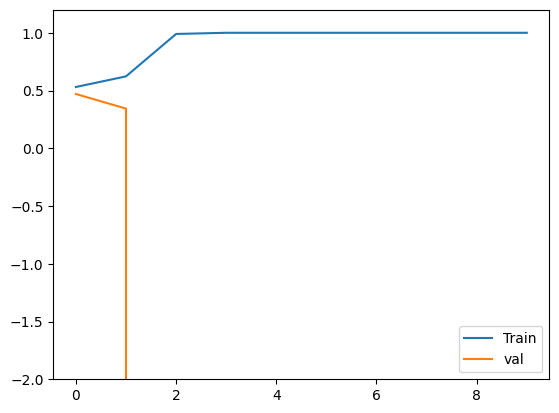

In [26]:
print(rsquare_train)
print(rsquare_val)

sns.lineplot(rsquare_train, label="Train")
sns.lineplot(rsquare_val, label="val")

plt.ylim(-2, 1.2)


In [27]:
# FINAL VERDICT - BEST DEGREE IS 2

### Finding the best regularisation model and best hyperparameter for them 

In [28]:
poly_final=PolynomialFeatures(degree=2)

x_train_scaled=pd.DataFrame(scaler.fit_transform(x_train),columns=x_train.columns)
x_val_scaled=pd.DataFrame(scaler.transform(x_val),columns=x_val.columns)

x_train_scaled_poly=pd.DataFrame(poly_final.fit_transform(x_train_scaled))
x_val_scaled_poly=pd.DataFrame(poly_final.transform(x_val_scaled))

In [29]:

ridge_train_mse=[]
ridge_val_mse=[]

lasso_train_mse=[]
lasso_val_mse=[]

en_train_mse=[]
en_val_mse=[]

ridge_train_rsquare=[]
ridge_val_rsquare=[]

lasso_train_rsquare=[]
lasso_val_rsquare=[]

en_train_rsquare=[]
en_val_rsquare=[]


for i in np.arange(0,1000,0.1):
    ridge=Ridge(alpha=i)
    lasso=Lasso(alpha=i)
    en=ElasticNet(alpha=i)

    ridge.fit(x_train_scaled_poly,y_train)
    lasso.fit(x_train_scaled_poly,y_train)
    en.fit(x_train_scaled_poly,y_train)


    y_train_pred_ridge=ridge.predict(x_train_scaled_poly)
    y_val_pred_ridge=ridge.predict(x_val_scaled_poly)

    ridge_train_mse_ins=mean_squared_error(y_train,y_train_pred_ridge)
    ridge_val_mse_ins=mean_squared_error(y_val,y_val_pred_ridge)

    ridge_train_rsquare_ins=r2_score(y_train,y_train_pred_ridge)
    ridge_val_rsquare_ins=r2_score(y_val,y_val_pred_ridge)

    ridge_train_mse.append(ridge_train_mse_ins)
    ridge_val_mse.append(ridge_val_mse_ins)
    ridge_train_rsquare.append(ridge_train_rsquare_ins)
    ridge_val_rsquare.append(ridge_val_rsquare_ins)



    y_train_pred_lasso=lasso.predict(x_train_scaled_poly)
    y_val_pred_lasso=lasso.predict(x_val_scaled_poly)

    lasso_train_mse_ins=mean_squared_error(y_train,y_train_pred_lasso)
    lasso_val_mse_ins=mean_squared_error(y_val,y_val_pred_lasso)

    lasso_train_rsquare_ins=r2_score(y_train,y_train_pred_lasso)
    lasso_val_rsquare_ins=r2_score(y_val,y_val_pred_lasso)

    lasso_train_mse.append(lasso_train_mse_ins)
    lasso_val_mse.append(lasso_val_mse_ins)
    lasso_train_rsquare.append(lasso_train_rsquare_ins)
    lasso_val_rsquare.append(lasso_val_rsquare_ins)



    y_train_pred_en=en.predict(x_train_scaled_poly)
    y_val_pred_en=en.predict(x_val_scaled_poly)

    en_train_mse_ins=mean_squared_error(y_train,y_train_pred_en)
    en_val_mse_ins=mean_squared_error(y_val,y_val_pred_en)

    en_train_rsquare_ins=r2_score(y_train,y_train_pred_en)
    en_val_rsquare_ins=r2_score(y_val,y_val_pred_en)

    en_train_mse.append(en_train_mse_ins)
    en_val_mse.append(en_val_mse_ins)
    en_train_rsquare.append(en_train_rsquare_ins)
    en_val_rsquare.append(en_val_rsquare_ins)


c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.297e+05, tolerance: 1.741e+02
Linear regression models with a zero l1 penalization strength are more efficiently fitted using one of 

0.40352017133330265
0.44626161130502795
0.4064707358353945
50
5.0
0.44626161130502795


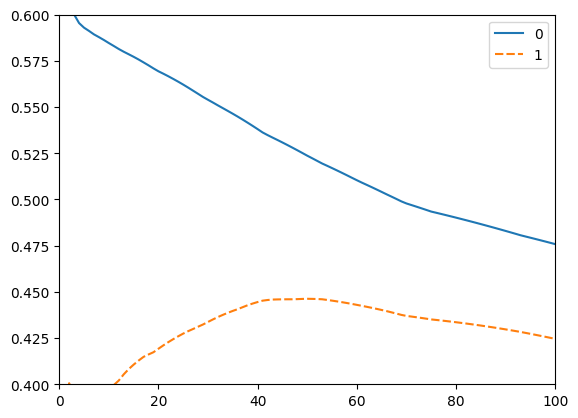

In [30]:
# sns.lineplot(data=[ridge_train_rsquare,ridge_val_rsquare])
# plt.ylim(0.4,0.65)
# plt.xlim(0,500)

sns.lineplot(data=[lasso_train_rsquare,lasso_val_rsquare])
plt.ylim(0.4,0.6)
plt.xlim(0,100)

# sns.lineplot(data=[en_train_rsquare,en_val_rsquare])
# plt.ylim(0.4,0.6)
# plt.xlim(0,10)

print(max(ridge_val_rsquare))
print(max(lasso_val_rsquare))
print(max(en_val_rsquare))


print(np.argmax(lasso_val_rsquare))
best_alpha=np.arange(0,1000,0.1)[np.argmax(lasso_val_rsquare)]
print(best_alpha)

best_accu=lasso_val_rsquare[np.argmax(lasso_val_rsquare)]
print(best_accu)


# LASSO IS CLEARLY THE BEST OUT OF THE THREE WITH BEST ALPHA VALUE OF 3


## Model creation with pipeline- regularisation, pipeline, polynomial regression

In [1]:
import pandas as pd
import numpy as np 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.pipeline import make_pipeline
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression,Lasso,Ridge,ElasticNet
from sklearn.metrics import r2_score, mean_squared_error
from tqdm import tqdm

In [2]:
x_data=pd.DataFrame(load_diabetes()['data'])
y_data=pd.DataFrame(load_diabetes()['target'])

In [3]:
x_mid,x_test,y_mid,y_test=train_test_split(x_data,y_data,random_state=42,test_size=0.2)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,random_state=42,test_size=0.2)

### Choosing the best polynomial degree

In [4]:


mse_train=[]
mse_val=[]
rsquare_train=[]
rsquare_val=[]

for i in range(1,11):
    model=make_pipeline(PolynomialFeatures(i),StandardScaler(),LinearRegression())
    model.fit(x_train,y_train)
    y_pred_train=model.predict(x_train)
    y_pred_val=model.predict(x_val)

    mse_train_ins=mean_squared_error(y_train,y_pred_train)
    mse_val_ins=mean_squared_error(y_val,y_pred_val)

    rsquare_train_ins=r2_score(y_train,y_pred_train)
    rsquare_val_ins=r2_score(y_val,y_pred_val)

    mse_train.append(mse_train_ins)
    mse_val.append(mse_val_ins)
    rsquare_train.append(rsquare_train_ins)
    rsquare_val.append(rsquare_val_ins)



(-2.0, 1.2)

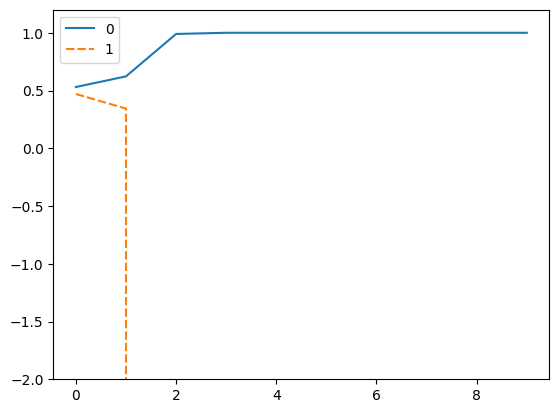

In [5]:
sns.lineplot(data=[rsquare_train,rsquare_val])
plt.ylim(-2, 1.2)

# POLYNOMIAL DEGREE OF 2 IS CLEARLY THE BEST

### Choosing the best regularisation model and its hyperparameter

In [6]:
rsquare_ridge_train=[]
rsquare_ridge_val=[]

for i in tqdm(np.arange(0,1000,0.5)):

    model=make_pipeline(PolynomialFeatures(2),StandardScaler(),Ridge(alpha=i))
    model.fit(x_train,y_train)
    y_train_pred_ridge=model.predict(x_train)
    y_val_pred_ridge=model.predict(x_val)

    rsquare_ridge_train_ins=r2_score(y_train,y_train_pred_ridge)
    rsquare_ridge_val_ins=r2_score(y_val,y_val_pred_ridge)

    rsquare_ridge_train.append(rsquare_ridge_train_ins)
    rsquare_ridge_val.append(rsquare_ridge_val_ins)


100%|██████████| 2000/2000 [00:09<00:00, 214.78it/s]


In [7]:
rsquare_lasso_train=[]
rsquare_lasso_val=[]

for i in tqdm(np.arange(0,1000,0.5)):

    model=make_pipeline(PolynomialFeatures(2),StandardScaler(),Lasso(alpha=i))
    model.fit(x_train,y_train)
    y_train_pred_lasso=model.predict(x_train)
    y_val_pred_lasso=model.predict(x_val)

    rsquare_lasso_train_ins=r2_score(y_train,y_train_pred_lasso)
    rsquare_lasso_val_ins=r2_score(y_val,y_val_pred_lasso)

    rsquare_lasso_train.append(rsquare_lasso_train_ins)
    rsquare_lasso_val.append(rsquare_lasso_val_ins)

  0%|          | 0/2000 [00:00<?, ?it/s]c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.297e+05, tolerance: 1.741e+02
Linear regression models with a zero l1 penalization strength a

In [8]:
rsquare_en_train=[]
rsquare_en_val=[]

for i in tqdm(np.arange(0,1000,0.5)):

    model=make_pipeline(PolynomialFeatures(2),StandardScaler(),ElasticNet(alpha=i))
    model.fit(x_train,y_train)
    y_train_pred_en=model.predict(x_train)
    y_val_pred_en=model.predict(x_val)

    rsquare_en_train_ins=r2_score(y_train,y_train_pred_en)
    rsquare_en_val_ins=r2_score(y_val,y_val_pred_en)

    rsquare_en_train.append(rsquare_en_train_ins)
    rsquare_en_val.append(rsquare_en_val_ins)

  0%|          | 0/2000 [00:00<?, ?it/s]c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\base.py:1365: UserWarning: With alpha=0, this algorithm does not converge well. You are advised to use the LinearRegression estimator
  return fit_method(estimator, *args, **kwargs)
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: UserWarning: Coordinate descent with no regularization may lead to unexpected results and is discouraged.
  model = cd_fast.enet_coordinate_descent(
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.297e+05, tolerance: 1.741e+02
Linear regression models with a zero l1 penalization strength a

In [17]:
# sns.lineplot(data=[rsquare_ridge_train,rsquare_ridge_val])
# plt.ylim(0,1)
# plt.xlim(0,10)

# sns.lineplot(data=[rsquare_lasso_train,rsquare_lasso_val])
# plt.ylim(0,1)
# plt.xlim(0,50)

# sns.lineplot(data=[rsquare_en_train,rsquare_en_val])
# plt.ylim(0,1)
# plt.xlim(0,10)

print(max(rsquare_ridge_val))
print(max(rsquare_lasso_val))
print(max(rsquare_en_val))

print(np.argmax(rsquare_lasso_val))
print('best alpha is',np.arange(0,1000,0.5)[np.argmax(rsquare_lasso_val)])
print('best accuracy is',rsquare_lasso_val[np.argmax(rsquare_lasso_val)])

# CLEARLY LASSO WITH ALPHA 5 IS THE BEST OPTION. DOING ONE FINAL CHECK

model_final=make_pipeline(PolynomialFeatures(2),StandardScaler(),Lasso(alpha=5))
model_final.fit(x_train,y_train)
val_pred_final=model_final.predict(x_val)
print(r2_score(y_val,val_pred_final))


0.4150167842534124
0.4524022051568095
0.4158039092159933
10
best alpha is 5.0
best accuracy is 0.4524022051568095
0.4524022051568095


### Final run of the model on the test set

In [20]:
final_test_model=make_pipeline(PolynomialFeatures(2),StandardScaler(),Lasso(alpha=5))
final_test_model.fit(x_train,y_train)
y_test_pred=final_test_model.predict(x_test)
print('final test score of the model is',r2_score(y_test,y_test_pred))


final test score of the model is 0.5011345643265446


# Chapter 8 - intro to logistic regression

In [ ]:
'''
How does logisitc regression work

1 - Z: Log odds
    - lets say that we have only 1 feature. We need to create a seperator line which seperates both the classes
    - Whenever we put values of a point on that line, magnitude and sign tells us that how far is that point from the seperator line
    - more the distance, more the confidence of being of a certain class
    - To define a seperator line, we set up weights similar to regression
        in the format: w0+w1x1+w2x3......=z
2 - sigmoid function
    - To convert z into binary, we use sigmoid function
        sigmoid = 1/(1+e**-z)
3 - loss function: binary cross entropy: 
    -1/n((y*(logy')+(1-y)*(log(1-y'))))
4 - gradient descent for this is complicated. Direct answer below
    - -x(y-y')/n
5 - For regularization, instead of alpha, lambda is used
    Similar to linear regression
    - ridge (L2): add weight of squares, i.e loss + lambda(sum(wi**2))
    - Lasso (L1): add weight of squares, i.e loss + lambda(sum(|wi|))
'''

# Chapter 9 - intro to logistic regression 2

In [ ]:
'''

For multiclass, logistic regression, we use OVR, i.e one vs rest. Hence, for n classes, there will be n models

- use this parameter while calling the model class (multi_class='ovr')
'''

## Logistic Regression implementation

In [13]:
import pandas as pd 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
import numpy as np
import seaborn as sns

In [3]:
df_churn=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\13_intro_to_ml_nn\13.9_intro_to_ml_logistic_regression_2\churn_logistic.csv')
df_churn_2=df_churn[['Day Mins', 'Eve Mins', 'Night Mins', 'CustServ Calls', 'Account Length']]
df_y=df_churn['Churn']

In [15]:
# Step 1 - Train test split 
x_mid,x_test,y_mid,y_test=train_test_split(df_churn_2,df_y,test_size=0.2,random_state=42)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,test_size=0.2,random_state=42)


# Step 2 - Scaling
scaler=StandardScaler()

# Step 3 - Choosing the best hyperparameter

def accu (y_act,y_pred):
    return((np.sum(y_act==y_pred))/y_act.shape[0])

i_vals=[]
train_acc=[]
val_acc=[]

for i in np.arange(0.01,5000,0.05):
    i_vals.append(i)
    pl=make_pipeline(scaler,LogisticRegression(C=1/i))
    pl.fit(x_train,y_train)
    y_train_pred=pl.predict(x_train)
    y_val_pred=pl.predict(x_val)
    train_acc.append(accu(y_train,y_train_pred))
    val_acc.append(accu(y_val,y_val_pred))

    # you can choose other regularisation models here as well. In fact you can iterate to see the best one



<Axes: >

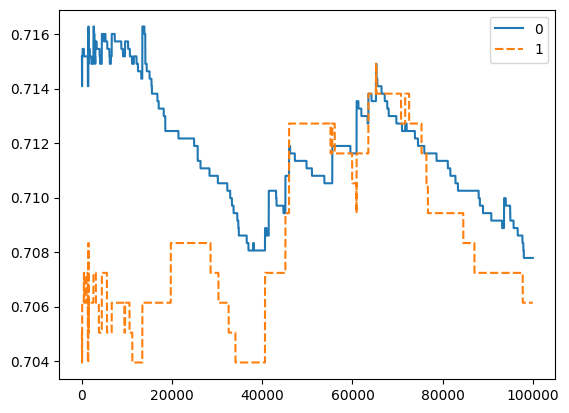

In [17]:
# Step 4 - Final Validation
sns.lineplot(data=[train_acc,val_acc])

## Multiclass Classification using logisitc regression

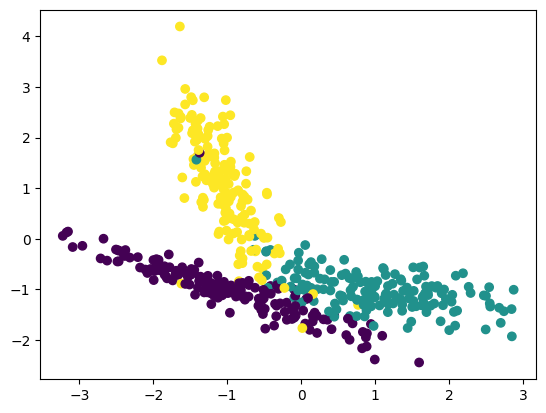

In [16]:
# dataset creation with 3 classes
from sklearn.datasets import make_classification
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.inspection import DecisionBoundaryDisplay

X, y = make_classification(n_samples= 498,
                           n_features= 2,
                           n_classes = 3,
                           n_redundant=0,
                           n_clusters_per_class=1,
                           random_state=5)
y=y.reshape(len(y), 1)

plt.scatter(X[:, 0], X[:, 1], c = y)
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

X_tr_cv, X_test, y_tr_cv, y_test = train_test_split(X, y, test_size=0.2, random_state=4)
X_train, X_val, y_train, y_val = train_test_split(X_tr_cv, y_tr_cv, test_size=0.25,random_state=4)
X_train.shape

In [ ]:
model=LogisticRegression(multi_class='ovr')
model.fit(X_train,y_train)

print(f'Training Accuracy:{model.score(X_train,y_train)}')
print(f'Validation Accuracy :{model.score(X_val,y_val)}')
print(f'Test Accuracy:{model.score(X_test,y_test)}')


# Chapter 10 - ML Classification metrics

In [ ]:
'''
In real world problems, we cant trust accuracy, because example for spam detection, with 10% occurence rate, if someone says all are non spam, he will be 90% accurate
hence, we have the following important metric


1 - Precision: TP/(TP+FP): Out of the predicted true,how many were actually true
    Very high thresholds, i.e very high signals before concluding it to be true, i.e we have to be very sure before flagging a case to be true
    False negatives are traded off with false positive
    Important in cases like following
        Detection of criminals: So that innocent folks dont end up in jail
        Detection of spam emails: so that important emails dont end up in spam

2 - Recall/Sensitivity: TP/(TP+FN): Out of the actual true, how many were we able  to flag true
    Low thresholds, i.e we flag even at minimal signals, i.e we dont have to be absolutely confident to flag it to be true
    False positives are traded off with false negatives
    Important in cases like following
    Cancer Detection - we cant let a patient leave with the idea that you dont have even at slightest signal

3 - To balance preciosion and recall, we use F1 score which is harmonic mean of both
    2*precision*recall(precision+Recall)

Please note that trade off between precicion and recall is just a play of thresholding
by default, thresold if of 0.5

'''

## Implementing CM metrics

In [40]:
import pandas as pd
import numpy as np 
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score,recall_score,precision_score,confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

In [7]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\13_intro_to_ml_nn\13.10_intro_to_ml_classification_metrics\Spam_finalData.csv')

In [11]:
x=df.drop(['label_num'],axis=1)
y=df['label_num']

In [17]:
x_mid,x_test,y_mid,y_test=train_test_split(x,y,random_state=42,train_size=0.8)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,random_state=42,train_size=0.8)

In [ ]:
model=LogisticRegression()
model.fit(x_train,y_train)
print(model.score(x_test,y_test))

0.9381642512077295


[[697  45]
 [ 19 274]]


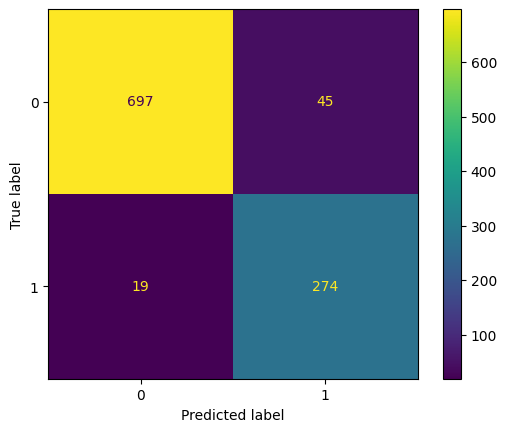

In [ ]:
y_test_pred=model.predict(x_test)
confusion_mat=confusion_matrix(y_test,y_test_pred)
print(confusion_mat)
ConfusionMatrixDisplay(confusion_mat).plot()


In [26]:
print(precision_score(y_test,y_test_pred))
print(f1_score(y_test,y_test_pred))
print(recall_score(y_test,y_test_pred))

0.8589341692789969
0.8954248366013072
0.9351535836177475


In [32]:
print(model.predict_proba(x_test))
print(y_test_pred)

[[0.95658391 0.04341609]
 [0.43891205 0.56108795]
 [0.96706107 0.03293893]
 ...
 [0.30817197 0.69182803]
 [0.68110123 0.31889877]
 [0.99367447 0.00632553]]
[0 1 0 ... 1 0 0]


## Precision vs recall tradeoff based on threshold

In [43]:

precision_score_list=[]
f1_score_list=[]
recall_score_list=[]
for i in np.arange(0,1,0.01):
    model.predict_proba(x_test)
    precision_score_list.append(precision_score(y_test,np.where(model.predict_proba(x_test)[:,1]>=i,1,0)))
    f1_score_list.append(f1_score(y_test,np.where(model.predict_proba(x_test)[:,1]>=i,1,0)))
    recall_score_list.append(recall_score(y_test,np.where(model.predict_proba(x_test)[:,1]>=i,1,0)))

c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\Mayank Bhatia\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

<Axes: >

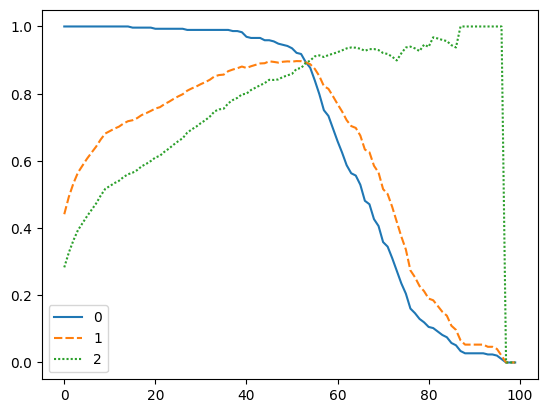

In [ ]:
sns.lineplot([recall_score_list,f1_score_list,precision_score_list])
'''
# NOTE THAT  IN MOST CASES, F1 SCORE PEAKS WHERE RECALL AND THRESHOLD LINES MEET
In the below graph, precision suddenly drop to zero in extreme thresnhold cases
That is because while false positives become 0, even the true positives become 0
hence, tp/(tp+fp) becomes 0/(0+0)
'''

# Chapter 11 - ML Classification metrics cont. and imbalanced data

In [ ]:
'''
TPR (True positive rate)=Recall=Sensitivity: Out of total postivies, how much were we able to capture
    =TP/(TP+FN)

FPR (False positive rate): Out of total negatives, how much are being falsesly being flagged as positive
    = FP(TN+FP)

- ROC-AUC: TPR and FPR become important because these are the tradeoffs when deciding the threshold of a model
    With increase in threshold, TPR and FPR both increase. However, best threshold is considered to be the inflexion/apex point which is farthest from the 0.5 coin-flip line and closest to the top left corner

NOTE THAT ROC-AUC CAN NOT ALWAYS BE TRUSTED IN CASE OF LIMITED THRESOLD VLAUES OR IN CASE OF HEAVILIY IMBALANCED DATA
    HENCE ALWAYS DECIDE USING BOTH ROC-AUC AND PRECIOSION-RECALL CURVE


imbalanced data handling
- Undersampling: Removal of random majority class
- Oversampling: Duplicattion of random minority class
- SMOTE - Created fake calculated values for minority class (BEST WAY TO DO)

'''

## Implementation of ROC-AUC curve

In [29]:
import pandas as pd
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve,precision_recall_curve,precision_score,recall_score,f1_score

In [ ]:
df=pd.read_csv(r'C:\Users\Mayank Bhatia\Documents\GitHub\DSML\13_intro_to_ml_nn\13.10_intro_to_ml_classification_metrics\Spam_finalData.csv')

In [3]:
x=df.drop(['label_num'],axis=1)
y=df['label_num']


In [7]:
x_mid,x_test,y_mid,y_test=train_test_split(x,y,random_state=42,train_size=0.8)
x_train,x_val,y_train,y_val=train_test_split(x_mid,y_mid,random_state=42,train_size=0.8)

In [17]:
model=LogisticRegression()
model.fit(x_train,y_train)


,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [27]:
y_pred_train=model.predict(x_train)
y_pred_test=model.predict(x_test)

y_pred_train=model.predict_proba(x_train)[:,1]
y_pred_test=model.predict_proba(x_test)[:,1]

In [50]:
preciosion, recall, thresholds=precision_recall_curve(y_train,y_pred_train)
fpr, tpr, thresholds_2=roc_curve(y_train,y_pred_train)

<Axes: >

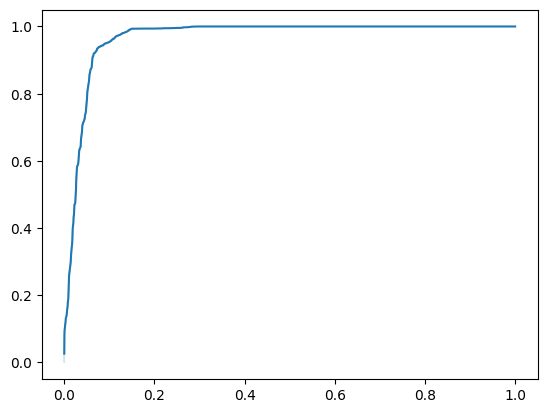

In [51]:
sns.lineplot(x=fpr,y=tpr)


<Axes: >

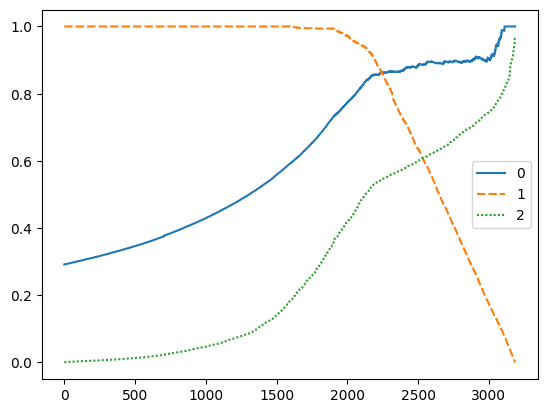

In [52]:
sns.lineplot(data=[preciosion,recall,thresholds])